In [2]:
import pandas as pd 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, accuracy_score

# Machine Learning Models
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.svm import SVC

# 1. Load Data & Parse Dates
df = pd.read_csv(r"C:\Users\joshh\Machine_Learning\Audiology_Project\Audio_Data.csv")
df['INVESTDATE'] = pd.to_datetime(df['INVESTDATE'], format="%d/%m/%Y")

# Define frequency columns
LeftSC = [f'L{f}C' for f in [250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000, 8000]]
RightSC = [f'R{f}C' for f in [250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000, 8000]]

# Replace 0s with NaN for audiological thresholds
df[LeftSC] = df[LeftSC].replace(0, np.nan)
df[RightSC] = df[RightSC].replace(0, np.nan)

# Calculate overall means
df['Right_Mean'] = df[RightSC].mean(axis=1)
df['Left_Mean'] = df[LeftSC].mean(axis=1)

# Sort and keep the record with the fewest NaNs per visit
df = df.sort_values(by=['Unique PID', 'INVESTDATE', 'CURVE'])
df['_nan_count'] = df.isnull().sum(axis=1)
df = df.loc[df.groupby(['Unique PID', 'INVESTDATE', 'CURVE'])['_nan_count'].idxmin()].drop(columns=['_nan_count'])

# 2. Grouped Shifting (Prevents cross-patient data leakage)
shift_cols = LeftSC + RightSC + ['INVESTDATE', 'CURVE', 'Right_Mean', 'Left_Mean']
shifted_df = df[shift_cols].groupby(df['Unique PID']).shift(-1)

# Rename shifted columns
rename_dict = {col: f'B{col}' for col in LeftSC + RightSC}
rename_dict.update({
    'INVESTDATE': 'next_DATE', 
    'CURVE': 'next_CURVE', 
    'Right_Mean': 'next_Right_Mean', 
    'Left_Mean': 'next_Left_Mean'
})
shifted_df = shifted_df.rename(columns=rename_dict)

# Join shifted columns back to main dataframe safely
df = pd.concat([df, shifted_df], axis=1)

# Assign next_PID since patients stay the same within their group
df['next_PID'] = df['Unique PID']

# Define Baseline frequency columns
BLeftSC = [f'BL{f}C' for f in [250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000, 8000]]
BRightSC = [f'BR{f}C' for f in [250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000, 8000]]

# 3. Condition & BC Calculations
condition = (
    (df['Unique PID'] == df['next_PID']) & 
    (df['INVESTDATE'] == df['next_DATE']) & 
    (df['CURVE'] == 0) & 
    (df['next_CURVE'] == 10)
)

df['RAC_BC'] = np.where(condition, np.abs(df['Right_Mean'] - df['next_Right_Mean']), np.nan)
df['LAC_BC'] = np.where(condition, np.abs(df['Left_Mean'] - df['next_Left_Mean']), np.nan)

df_end = df.dropna(subset=['RAC_BC', 'LAC_BC'], how='all').copy().reset_index(drop=True)
df_end['Ear_Asymmetry'] = np.abs(df_end['Right_Mean'] - df_end['Left_Mean'])

df_end.drop(columns=['next_PID', 'next_DATE', 'next_CURVE', 'next_Right_Mean', 'next_Left_Mean'], inplace=True, errors='ignore')

# 4. Frequency Subsets (Low vs High)
LLeftSC, LRightSC = LeftSC[:5], RightSC[:5]
HLeftSC, HRightSC = LeftSC[5:], RightSC[5:]
LBLeftSC, LBRightSC = BLeftSC[:5], BRightSC[:5]
HBLeftSC, HBRightSC = BLeftSC[5:], BRightSC[5:]

# Baseline (B) and Follow-up Means
df_end['BRight_Mean'] = df_end[BRightSC].mean(axis=1)
df_end['BLeft_Mean'] = df_end[BLeftSC].mean(axis=1)

df_end['HBRight_Mean'] = df_end[HBRightSC].mean(axis=1)
df_end['HBLeft_Mean'] = df_end[HBLeftSC].mean(axis=1)
df_end['HRight_Mean'] = df_end[HRightSC].mean(axis=1) 
df_end['HLeft_Mean'] = df_end[HLeftSC].mean(axis=1)    

df_end['LBRight_Mean'] = df_end[LBRightSC].mean(axis=1)
df_end['LBLeft_Mean'] = df_end[LBLeftSC].mean(axis=1)
df_end['LRight_Mean'] = df_end[LRightSC].mean(axis=1) 
df_end['LLeft_Mean'] = df_end[LLeftSC].mean(axis=1)    

# 5. Filtering Test Data
df_test = df_end[~((df_end['Treatment Cat'] == 'No Treatment') & ((df_end['Right_Mean'] > 30) | (df_end['Left_Mean'] > 30)))].copy()

# 6. Feature Engineering & Selection
engineered_cols = [
    'Right_Mean', 'Left_Mean', 'RAC_BC', 'LAC_BC', 'Ear_Asymmetry', 
    'BLeft_Mean', 'BRight_Mean', 'HBRight_Mean', 'HBLeft_Mean', 
    'HRight_Mean', 'HLeft_Mean', 'LBRight_Mean', 'LBLeft_Mean', 
    'LRight_Mean', 'LLeft_Mean'
]
frequency_cols = [c for c in df_test.columns if (c.startswith('R') or c.startswith('L') or c.startswith('B')) and c not in engineered_cols]
feature_cols = frequency_cols + engineered_cols

# Define X and y (Ensure 'Treatment Cat' is your correct target column)
X = df_test[feature_cols]
y = df_test['Treatment Cat']

# 7. Label Encoding & Train/Test Split
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
target_names = label_encoder.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=1415, stratify=y_encoded
)

# 8. Define Models Dictionary (Using Pipelines with SimpleImputer where needed)
models = {
    "XGBoost": xgb.XGBClassifier(
        n_estimators=150, max_depth=5, learning_rate=0.1, 
        subsample=0.8, colsample_bytree=0.8, random_state=1415, eval_metric='mlogloss'
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy='median'),
        RandomForestClassifier(n_estimators=150, max_depth=10, random_state=1415)
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=150, max_depth=5, learning_rate=0.1, 
        random_state=1415, verbose=-1
    ),
    "SVM (RBF Kernel)": make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(), 
        SVC(kernel='rbf', random_state=1415)
    )
}

# 9. Train and Evaluate All Models
for name, model in models.items():
    print("=" * 60)
    print(f"Model: {name}")
    print("=" * 60)
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=target_names))
    print("\n")
    print("\n")

Model: XGBoost
Accuracy: 0.8997

Classification Report:
              precision    recall  f1-score   support

     BCI_MEI       0.72      0.48      0.58      1578
          CI       0.75      0.65      0.69      1245
          HA       0.87      0.86      0.87      9044
No Treatment       0.94      1.00      0.97     13694

    accuracy                           0.90     25561
   macro avg       0.82      0.75      0.78     25561
weighted avg       0.89      0.90      0.89     25561





Model: Random Forest
Accuracy: 0.8888

Classification Report:
              precision    recall  f1-score   support

     BCI_MEI       0.78      0.26      0.39      1578
          CI       0.76      0.56      0.64      1245
          HA       0.84      0.88      0.86      9044
No Treatment       0.93      1.00      0.97     13694

    accuracy                           0.89     25561
   macro avg       0.83      0.67      0.71     25561
weighted avg       0.88      0.89      0.88     25561





Mode

Model: XGBoost
Accuracy: 0.8602
Macro ROC-AUC (OvR): 0.9670

Classification Report:
              precision    recall  f1-score   support

     BCI_MEI       0.46      0.80      0.58      1578
          CI       0.55      0.88      0.67      1245
          HA       0.95      0.67      0.78      9044
No Treatment       0.94      0.99      0.97     13694

    accuracy                           0.86     25561
   macro avg       0.72      0.84      0.75     25561
weighted avg       0.90      0.86      0.86     25561



Model: Random Forest
Accuracy: 0.8483
Macro ROC-AUC (OvR): 0.9609

Classification Report:
              precision    recall  f1-score   support

     BCI_MEI       0.41      0.74      0.53      1578
          CI       0.53      0.84      0.65      1245
          HA       0.94      0.64      0.76      9044
No Treatment       0.94      1.00      0.97     13694

    accuracy                           0.85     25561
   macro avg       0.70      0.81      0.73     25561
weighted 

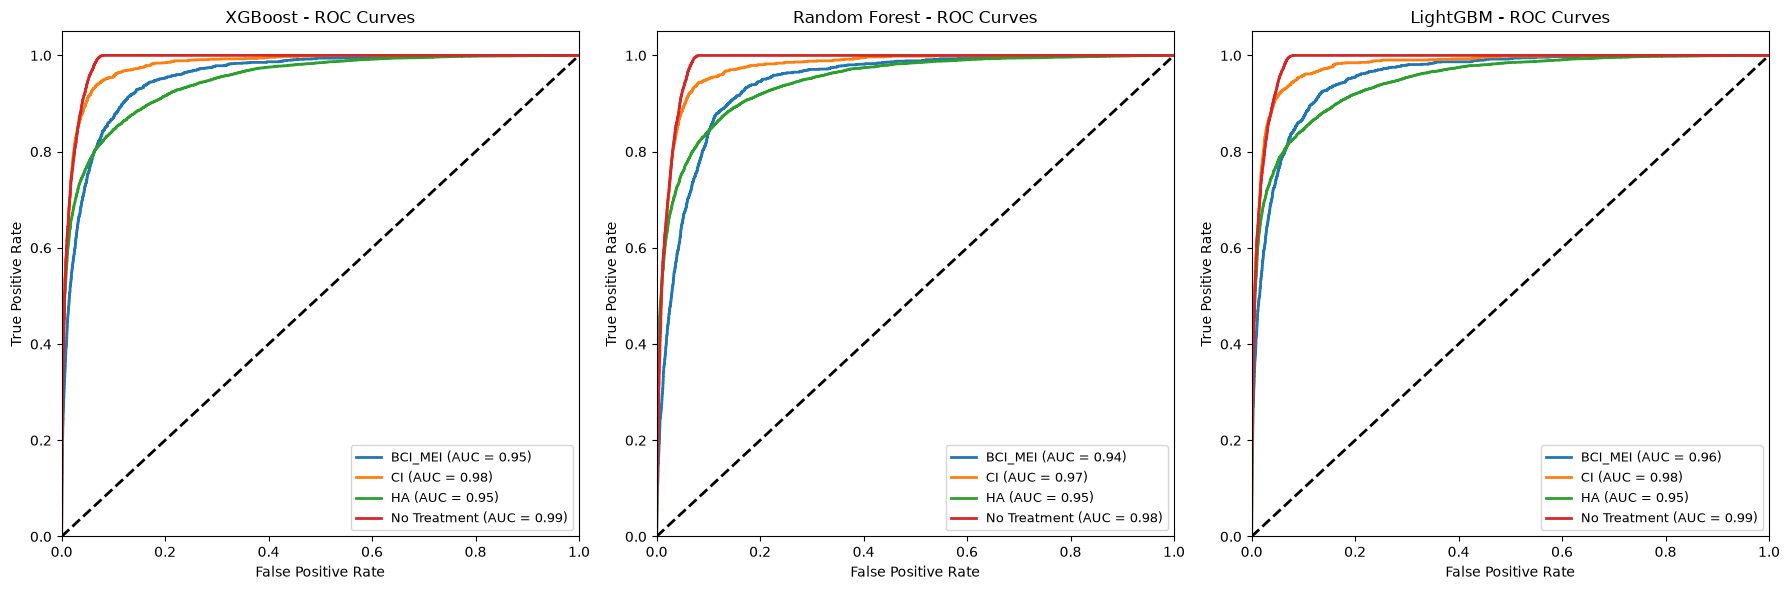

In [3]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score, roc_curve, auc
from sklearn.utils.class_weight import compute_sample_weight

# Machine Learning Models
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

# 1. Load Data & Parse Dates
df = pd.read_csv(r"C:\Users\joshh\Machine_Learning\Audiology_Project\Audio_Data.csv")
df['INVESTDATE'] = pd.to_datetime(df['INVESTDATE'], format="%d/%m/%Y")

# Define frequency columns
LeftSC = [f'L{f}C' for f in [250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000, 8000]]
RightSC = [f'R{f}C' for f in [250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000, 8000]]

# Replace 0s with NaN for audiological thresholds
df[LeftSC] = df[LeftSC].replace(0, np.nan)
df[RightSC] = df[RightSC].replace(0, np.nan)

# Calculate overall means
df['Right_Mean'] = df[RightSC].mean(axis=1)
df['Left_Mean'] = df[LeftSC].mean(axis=1)

# Sort and keep the record with the fewest NaNs per visit
df = df.sort_values(by=['Unique PID', 'INVESTDATE', 'CURVE'])
df['_nan_count'] = df.isnull().sum(axis=1)
df = df.loc[df.groupby(['Unique PID', 'INVESTDATE', 'CURVE'])['_nan_count'].idxmin()].drop(columns=['_nan_count'])

# 2. Grouped Shifting (Prevents cross-patient data leakage)
shift_cols = LeftSC + RightSC + ['INVESTDATE', 'CURVE', 'Right_Mean', 'Left_Mean']
shifted_df = df[shift_cols].groupby(df['Unique PID']).shift(-1)

# Rename shifted columns
rename_dict = {col: f'B{col}' for col in LeftSC + RightSC}
rename_dict.update({
    'INVESTDATE': 'next_DATE', 
    'CURVE': 'next_CURVE', 
    'Right_Mean': 'next_Right_Mean', 
    'Left_Mean': 'next_Left_Mean'
})
shifted_df = shifted_df.rename(columns=rename_dict)

# Join shifted columns back to main dataframe safely
df = pd.concat([df, shifted_df], axis=1)

# Assign next_PID since patients stay the same within their group
df['next_PID'] = df['Unique PID']

# Define Baseline frequency columns
BLeftSC = [f'BL{f}C' for f in [250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000, 8000]]
BRightSC = [f'BR{f}C' for f in [250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000, 8000]]

# 3. Condition & BC Calculations
condition = (
    (df['Unique PID'] == df['next_PID']) & 
    (df['INVESTDATE'] == df['next_DATE']) & 
    (df['CURVE'] == 0) & 
    (df['next_CURVE'] == 10)
)

df['RAC_BC'] = np.where(condition, np.abs(df['Right_Mean'] - df['next_Right_Mean']), np.nan)
df['LAC_BC'] = np.where(condition, np.abs(df['Left_Mean'] - df['next_Left_Mean']), np.nan)

df_end = df.dropna(subset=['RAC_BC', 'LAC_BC'], how='all').copy().reset_index(drop=True)
df_end['Ear_Asymmetry'] = np.abs(df_end['Right_Mean'] - df_end['Left_Mean'])

df_end.drop(columns=['next_PID', 'next_DATE', 'next_CURVE', 'next_Right_Mean', 'next_Left_Mean'], inplace=True, errors='ignore')

# 4. Frequency Subsets (Low vs High)
LLeftSC, LRightSC = LeftSC[:5], RightSC[:5]
HLeftSC, HRightSC = LeftSC[5:], RightSC[5:]
LBLeftSC, LBRightSC = BLeftSC[:5], BRightSC[:5]
HBLeftSC, HBRightSC = BLeftSC[5:], BRightSC[5:]

# Baseline (B) and Follow-up Means
df_end['BRight_Mean'] = df_end[BRightSC].mean(axis=1)
df_end['BLeft_Mean'] = df_end[BLeftSC].mean(axis=1)

df_end['HBRight_Mean'] = df_end[HBRightSC].mean(axis=1)
df_end['HBLeft_Mean'] = df_end[HBLeftSC].mean(axis=1)
df_end['HRight_Mean'] = df_end[HRightSC].mean(axis=1) 
df_end['HLeft_Mean'] = df_end[HLeftSC].mean(axis=1)    

df_end['LBRight_Mean'] = df_end[LBRightSC].mean(axis=1)
df_end['LBLeft_Mean'] = df_end[LBLeftSC].mean(axis=1)
df_end['LRight_Mean'] = df_end[LRightSC].mean(axis=1) 
df_end['LLeft_Mean'] = df_end[LLeftSC].mean(axis=1)    

# 5. Filtering Test Data
df_test = df_end[~((df_end['Treatment Cat'] == 'No Treatment') & ((df_end['Right_Mean'] > 30) | (df_end['Left_Mean'] > 30)))].copy()

# 6. Feature Engineering & Selection
engineered_cols = [
    'Right_Mean', 'Left_Mean', 'RAC_BC', 'LAC_BC', 'Ear_Asymmetry', 
    'BLeft_Mean', 'BRight_Mean', 'HBRight_Mean', 'HBLeft_Mean', 
    'HRight_Mean', 'HLeft_Mean', 'LBRight_Mean', 'LBLeft_Mean', 
    'LRight_Mean', 'LLeft_Mean'
]
frequency_cols = [c for c in df_test.columns if (c.startswith('R') or c.startswith('L') or c.startswith('B')) and c not in engineered_cols]
feature_cols = frequency_cols + engineered_cols

# Define X and y
X = df_test[feature_cols]
y = df_test['Treatment Cat']

# 7. Label Encoding & Train/Test Split
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
target_names = label_encoder.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=1415, stratify=y_encoded
)

# Binarize labels for multi-class ROC calculation
y_test_binarized = label_binarize(y_test, classes=np.unique(y_encoded))
n_classes = y_test_binarized.shape[1]

# Compute sample weights for gradient boosting models
sample_weights_train = compute_sample_weight(class_weight='balanced', y=y_train)

# 8. Define Models Dictionary (Excluding SVM)
models = {
    "XGBoost": xgb.XGBClassifier(
        n_estimators=150, max_depth=5, learning_rate=0.1, 
        subsample=0.8, colsample_bytree=0.8, random_state=1415, eval_metric='mlogloss'
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy='median'),
        RandomForestClassifier(
            n_estimators=150, max_depth=10, 
            class_weight='balanced_subsample',  
            random_state=1415
        )
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=150, max_depth=5, learning_rate=0.1, 
        class_weight='balanced',             
        random_state=1415, verbose=-1
    )
}

# 9. Train, Evaluate, and Plot ROC Curves for Each Model
plt.figure(figsize=(18, 6))

for idx, (name, model) in enumerate(models.items(), 1):
    print("=" * 60)
    print(f"Model: {name}")
    print("=" * 60)
    
    # Fit model
    if name == "XGBoost":
        model.fit(X_train, y_train, sample_weight=sample_weights_train)
    else:
        model.fit(X_train, y_train)
        
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)
    
    # Metrics
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    roc_auc_macro = roc_auc_score(y_test_binarized, y_prob, average='macro', multi_class='ovr')
    print(f"Macro ROC-AUC (OvR): {roc_auc_macro:.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=target_names))
    print("\n")
    
    # Subplot for ROC Curves
    plt.subplot(1, len(models), idx)
    
    for i, class_name in enumerate(target_names):
        fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_prob[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'{class_name} (AUC = {roc_auc:.2f})')
        
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{name} - ROC Curves')
    plt.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()